In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')



In [47]:
numerical_columns = list(df.dtypes[df.dtypes != 'object'].index)

numerical_columns.remove('converted')
numerical_columns

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [8]:
df.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [7]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
# For categorical features, replace them with 'NA'
for c in categorical_columns:
    df[c] = df[c].fillna('NA')
    
# For numerical features, replace them with zeros
for c in numerical_columns:
    df[c] = df[c].fillna(0)

In [10]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [12]:
df.nunique()

lead_source                    6
industry                       7
employment_status              5
location                       6
annual_income               4314
number_of_courses_viewed       7
interaction_count             14
lead_score                   100
converted                      2
dtype: int64

In [14]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

### Question 1: ROC AUC feature importance

In [17]:
# ROC AUC could also be used to evaluate feature importance of numerical variables.

# Let's do that

# For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
# Use the training dataset for that
# If your AUC is < 0.5, invert this variable by putting "-" in front

# (e.g. -df_train['balance'])

# AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

# Which numerical variable (among the following 4) has the highest AUC?

In [27]:
# get AUC for a numeric variable
numerical_columns

Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='object')

In [22]:
from sklearn.metrics import roc_auc_score

In [29]:
for f in numerical_columns:
    auc = roc_auc_score(y_train, df_train[f])
    # if AUC < 0.5, invert the variable
    if auc < 0.5:
        auc = roc_auc_score(y_train, -X_train[f])
    print(f"{f}: {auc:.3f}")

annual_income: 0.608
number_of_courses_viewed: 0.723
interaction_count: 0.765
lead_score: 0.788


#### Ans:1 lead_score: 0.788 has max AUC

In [48]:
def train(df_train, y_train, C=1.0):
    dicts=df_train[categorical_columns + numerical_columns].to_dict(orient='records')
    
    dv= DictVectorizer(sparse=False)
    X_train=dv.fit_transform(dicts)
    
    model= LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model
    

In [49]:
def predict(df, dv, model):
    dicts = df[categorical_columns + numerical_columns].to_dict(orient='records')
    
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[: , 1]
    
    return(y_pred)

In [52]:
dv, model = train(df_train, y_train)

y_pred = predict(df_val, dv, model)

auc = roc_auc_score(y_val, y_pred)
auc.round(3)

0.732

### Ans:2  AUC=0.732

### Question 3: Precision and Recall

In [57]:
# Now let's compute precision and recall for our model.

# Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
# For each threshold, compute precision and recall
# Plot them
# At which threshold precision and recall curves intersect? 
# Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest 
# absolute difference between precision and recall.

In [97]:
thresolds = np.arange(0.0,1.01,0.01)
thresolds

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [98]:
scores = []
for t in thresolds:
    convert_decision = (y_pred >= t)
    score = (y_val == convert_decision).mean()
    print('%0.2f %0.3f' % (t, score))
    scores.append(score)

scores

0.00 0.586
0.01 0.586
0.02 0.586
0.03 0.586
0.04 0.586
0.05 0.586
0.06 0.586
0.07 0.586
0.08 0.586
0.09 0.586
0.10 0.586
0.11 0.586
0.12 0.586
0.13 0.586
0.14 0.586
0.15 0.586
0.16 0.586
0.17 0.586
0.18 0.586
0.19 0.586
0.20 0.586
0.21 0.586
0.22 0.586
0.23 0.586
0.24 0.586
0.25 0.586
0.26 0.587
0.27 0.589
0.28 0.595
0.29 0.595
0.30 0.597
0.31 0.603
0.32 0.602
0.33 0.604
0.34 0.611
0.35 0.613
0.36 0.616
0.37 0.618
0.38 0.618
0.39 0.621
0.40 0.625
0.41 0.634
0.42 0.634
0.43 0.636
0.44 0.636
0.45 0.640
0.46 0.643
0.47 0.644
0.48 0.648
0.49 0.648
0.50 0.651
0.51 0.650
0.52 0.651
0.53 0.658
0.54 0.659
0.55 0.661
0.56 0.666
0.57 0.666
0.58 0.673
0.59 0.675
0.60 0.681
0.61 0.690
0.62 0.686
0.63 0.684
0.64 0.671
0.65 0.669
0.66 0.664
0.67 0.661
0.68 0.657
0.69 0.645
0.70 0.643
0.71 0.635
0.72 0.630
0.73 0.619
0.74 0.607
0.75 0.590
0.76 0.581
0.77 0.570
0.78 0.562
0.79 0.546
0.80 0.530
0.81 0.518
0.82 0.508
0.83 0.496
0.84 0.484
0.85 0.468
0.86 0.455
0.87 0.449
0.88 0.443
0.89 0.439
0.90 0.432

[0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.587,
 0.589,
 0.595,
 0.595,
 0.597,
 0.603,
 0.602,
 0.604,
 0.611,
 0.613,
 0.616,
 0.618,
 0.618,
 0.621,
 0.625,
 0.634,
 0.634,
 0.636,
 0.636,
 0.64,
 0.643,
 0.644,
 0.648,
 0.648,
 0.651,
 0.65,
 0.651,
 0.658,
 0.659,
 0.661,
 0.666,
 0.666,
 0.673,
 0.675,
 0.681,
 0.69,
 0.686,
 0.684,
 0.671,
 0.669,
 0.664,
 0.661,
 0.657,
 0.645,
 0.643,
 0.635,
 0.63,
 0.619,
 0.607,
 0.59,
 0.581,
 0.57,
 0.562,
 0.546,
 0.53,
 0.518,
 0.508,
 0.496,
 0.484,
 0.468,
 0.455,
 0.449,
 0.443,
 0.439,
 0.432,
 0.424,
 0.421,
 0.42,
 0.417,
 0.416,
 0.415,
 0.414,
 0.414,
 0.414,
 0.414]

In [99]:
score = []
precision = []
recall = []

for t in thresolds:
    convert_decision = (y_pred >= t)
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    if (tp + fp) == 0.0:
        p = 0.000001
    else:
        p = tp / (tp + fp)
        
    precision.append(p)
            
    if (tp + fp) == 0.0:
        r = 0.000001
    else:
        r = tp / (tp + fn)
    
    recall.append(r)
    
    #score.append((t, tp, fp, tn, fn, precision, recall))

In [80]:
precision

[0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.5865865865865866,
 0.5877632898696088,
 0.591321897073663,
 0.591321897073663,
 0.5925176946410515,
 0.5963302752293578,
 0.5961145194274029,
 0.5973360655737705,
 0.6016511867905057,
 0.6028955532574974,
 0.6047717842323651,
 0.6069182389937107,
 0.6073684210526316,
 0.6095238095238096,
 0.6128342245989304,
 0.6190476190476191,
 0.6200873362445415,
 0.6225165562913907,
 0.623608017817372,
 0.6281179138321995,
 0.6320645905420992,
 0.6343457943925234,
 0.6382978723404256,
 0.6399521531100478,
 0.6436363636363637,
 0.6467661691542289,
 0.6494325346784363,
 0.6580310880829016,
 0.6618229854689565,
 0.6675712347354138,
 0.675,
 0.6789772727272727,
 0.6896046852122987,
 0.6956521739130435,
 0.7063369397217929,
 0.719047619047619,
 0.7259136212624585,
 0.7327586206896551,
 0.72987477

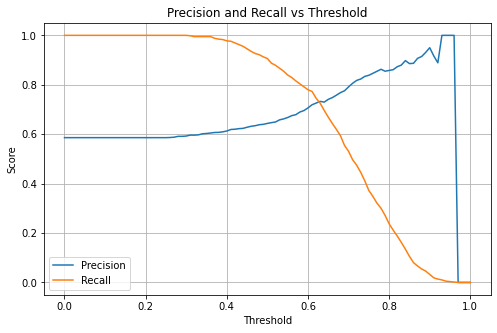

In [100]:
# Plot Precision and Recall vs Threshold
plt.figure(figsize=(8,5))
plt.plot(thresolds, precision, label='Precision')
plt.plot(thresolds, recall, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [82]:
## Now try it with sklearn library
from sklearn.metrics import precision_score, recall_score

In [101]:
precision = []
recall = []
for t in thresolds:
    convert_decision = (y_pred >= t)
    p = precision_score(y_val, convert_decision)
    precision.append(p)
    
    r = recall_score(y_val, convert_decision)
    recall.append(r)
    

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

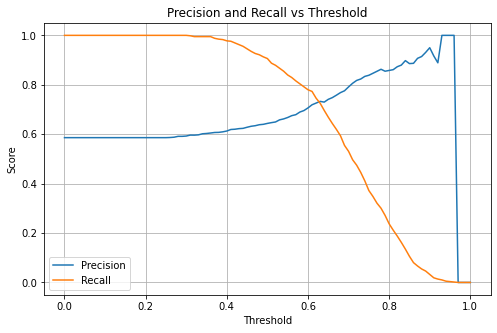

In [102]:
# Plot Precision and Recall vs Threshold
plt.figure(figsize=(8,5))
plt.plot(thresolds, precision, label='Precision')
plt.plot(thresolds, recall, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [115]:
# Find threshold where precision and recall intersect
diff = np.abs(np.array(precision) - np.array(recall))
diff

array([0.414     , 0.414     , 0.414     , 0.414     , 0.414     ,
       0.414     , 0.414     , 0.414     , 0.414     , 0.414     ,
       0.414     , 0.414     , 0.414     , 0.414     , 0.414     ,
       0.414     , 0.414     , 0.414     , 0.414     , 0.414     ,
       0.414     , 0.414     , 0.414     , 0.414     , 0.414     ,
       0.414     , 0.41341341, 0.41223671, 0.4086781 , 0.4086781 ,
       0.40748231, 0.40196324, 0.39876603, 0.39754448, 0.39322936,
       0.39198499, 0.39010876, 0.38113637, 0.37727322, 0.37341134,
       0.36498148, 0.3570616 , 0.34919594, 0.33994078, 0.33202338,
       0.31727458, 0.30308899, 0.29227537, 0.28320383, 0.27301713,
       0.26250698, 0.24060584, 0.22940706, 0.20886311, 0.19312582,
       0.17201921, 0.15435154, 0.13672239, 0.11414958, 0.0961567 ,
       0.07352654, 0.05398992, 0.01982017, 0.00750265, 0.03362904,
       0.07207881, 0.10467116, 0.13837489, 0.17435527, 0.22104882,
       0.26063188, 0.30950715, 0.34324433, 0.37795136, 0.42264

In [123]:
#  Ignore thresholds at which both metrics are zero
nonzero_indices = np.where(diff > 0)[0]
nonzero_indices

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
       68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84,
       85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96], dtype=int64)

In [124]:
# Get index where difference between both score is minimum
min_nonzero_idx = nonzero_indices[np.argmin(diff[nonzero_indices])]
min_nonzero_idx

63

In [125]:
# Find value of thresold at that index
best_thresold = thresolds[min_nonzero_idx]
best_thresold

0.63

### Ans:3 The smallest absolute difference between precision and recall = 0.63

## Question 4: F1 score

In [130]:

# Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

# This is the formula for computing F1:

# F
# 1
# =
# 2
# ⋅
# P
# ⋅
# R
# P
# +
# R

# Where 
# P
#  is precision and 
# R
#  is recall.

# Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

# At which threshold F1 is maximal?

SyntaxError: invalid syntax (<ipython-input-130-80816a312d0f>, line 1)

In [136]:
def precision_recall(y_val, y_pred, t):
    precision = []
    recall = []
    for t in thresolds:
        convert_decision = (y_pred >= t)
        p = precision_score(y_val, convert_decision)
        precision.append(p)

        r = recall_score(y_val, convert_decision)
        recall.append(r)
    return precision, recall

In [141]:
def f1(precision, recall):
    f1_score=[]
    
    for p, r in zip(precision, recall):
        if (p + r) == 0.0:
            f1 = 0.0
        else:
            f1 = 2 * ((p * r)/(p + r))
            f1_score.append(f1)

    return f1_score

In [142]:
for t in thresolds:
    precision, recall = precision_recall(y_val, y_pred, t)
    f1_score = f1(precision, recall)

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

...

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\7N\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1245: UndefinedMetricWarning: Precision is ill-defin

In [145]:
max_f1_idx = f1_score.index(max(f1_score))

In [148]:
thresold_max_f1 = thresolds[max_f1_idx]
thresold_max_f1.round(2)

0.41

### Ans:4 threshold F1 is maximal at 0.41

### Question 5: 5-Fold CV

In [153]:
# Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

# KFold(n_splits=5, shuffle=True, random_state=1)
# Iterate over different folds of df_full_train
# Split the data into train and validation
# Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
# Use AUC to evaluate the model on validation
# How large is standard deviation of the scores across different folds?

In [195]:
def train(df_train, y_train, C=1.0):
    dicts=df_train[categorical_columns + numerical_columns].to_dict(orient='records')
    
    dv= DictVectorizer(sparse=False)
    X_train=dv.fit_transform(dicts)
    
    model= LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model
    

In [171]:
#dv, model = train(df_train, y_train)

In [172]:
def predict(df, dv, model):
    dicts = df[categorical_columns + numerical_columns].to_dict(orient='records')
    
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[: , 1]
    
    return(y_pred)

In [173]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

In [174]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [196]:
scores = []

for train_idx, val_idx in tqdm(kfold.split(df_full_train)):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]
    
    y_train = df_train.converted.values
    y_val = df_val.converted.values
    
    dv, model = train(df_train, y_train)
    
    y_pred = predict(df_val, dv, model)
    
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)
    
    

0it [00:00, ?it/s]

In [197]:
#check avg and mean for different scores
np.mean(scores), np.std(scores)

(0.7317269710972524, 0.006853233151022138)

In [198]:
np.std(scores).round(3)

0.007

### Ans:5 Standard deviation of the scores across different folds= 0.007

### Question 6: Hyperparameter Tuning

In [203]:
# Now let's use 5-Fold cross-validation to find the best parameter C

# Iterate over the following C values: [0.000001, 0.001, 1]
# Initialize KFold with the same parameters as previously
# Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
# Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).
# Which C leads to the best mean ROC AUC?

In [204]:
def train(df_train, y_train, C=1.0):
    dicts=df_train[categorical_columns + numerical_columns].to_dict(orient='records')
    
    dv= DictVectorizer(sparse=False)
    X_train=dv.fit_transform(dicts)
    
    model= LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model
    

In [205]:
def predict(df, dv, model):
    dicts = df[categorical_columns + numerical_columns].to_dict(orient='records')
    
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[: , 1]
    
    return(y_pred)

In [206]:
# change no. of sprint 

n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    scores = []
    
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)

        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007


### Ans:6 C=0.001 leads to the best mean ROC AUC=0.749